# 01. 데이터 분석 · 전처리 · 기본 모델

**목적:** 15분 평균 전력(최대수요전력 기준)을 구간이 끝나기 전에 더 정확히 예측할 수 있는지 확인한다.

1. 원본 데이터 확인
2. 전처리: 1초 → 10초 평균, 규모 맞추기
3. 시간대별 부하 패턴
4. 15분 구간 평균 분포와 평가용 목표전력
5. 학습 샘플 만들기
6. 기존 계산식의 한계 확인
7. 기본 모델 (LightGBM 기본값) vs 기존 계산식
8. 정리

In [ ]:
import matplotlib.pyplot as plt
import koreanize_matplotlib  # 한글 폰트 자동 설정
import numpy as np
import pandas as pd
from lightgbm import LGBMRegressor

plt.rcParams["figure.figsize"] = (12, 3.5)
plt.rcParams["axes.unicode_minus"] = False

CSV_PATH = r"/home/gmlck/projects/power-edge/data/mvlv-transformer.csv"

## 1. 원본 데이터 확인

In [ ]:
# 컬럼 구성만 먼저 확인 (앞 5줄)
df = pd.read_csv(CSV_PATH, encoding="utf-8-sig")
print(df.head())

,timestamp,active_power,reactive_power,apparent_power,current,voltage
0,2017-12-11 18:43:52-02,8.22051,213.575,213.733,0.031497,6816.27
1,2017-12-11 18:43:53-02,11.50870,213.423,213.733,0.031358,6818.05
2,2017-12-11 18:43:54-02,-6.57641,-207.053,207.157,0.030559,6815.92
3,2017-12-11 18:43:55-02,3.28821,213.708,213.733,0.031567,6818.64
4,2017-12-11 18:43:56-02,0.00000,213.733,213.733,0.031358,6816.72


In [ ]:
# 분석에는 시각과 유효전력만 사용
df = pd.read_csv(CSV_PATH, usecols=["timestamp", "active_power"])

print(f"행 수: {len(df):,}")
print(df.dtypes)
print()
print("결측치 개수")
print(df.isna().sum())

행 수: 3,505,095
timestamp           str
active_power    float64
dtype: object

결측치 개수
timestamp       0
active_power    0
dtype: int64


In [ ]:
# 시각 문자열 예: "2017-12-11 18:43:52-02"
df["timestamp"] = pd.to_datetime(df["timestamp"].str[:19])

# W -> kW, 음수(측정 잡음)는 0으로
df["kw"] = df["active_power"].clip(lower=0) / 1000

df = df.sort_values("timestamp").drop_duplicates("timestamp")
df = df.set_index("timestamp")

print(f"기간: {df.index.min()} ~ {df.index.max()}")
df["kw"].describe()

기간: 2017-12-11 18:43:52 ~ 2018-04-03 18:48:48


count    3.435475e+06
mean     4.024914e+02
std      2.935505e+02
min      0.000000e+00
25%      3.355940e+01
50%      5.195080e+02
75%      6.834630e+02
max      9.526880e+02
Name: kw, dtype: float64

In [ ]:
# 측정 간격 확인: 1초가 대부분이어야 하고, 큰 간격은 수집 누락
gap = df.index.to_series().diff().dt.total_seconds()
print(gap.value_counts().head())
print()
print("1분 넘게 끊긴 곳:", (gap > 60).sum(), "군데")
print("가장 긴 누락:", pd.Timedelta(seconds=gap.max()))

timestamp
1.0      3349730
6.0        53028
30.0       16555
300.0       6928
150.0       5643
Name: count, dtype: int64

1분 넘게 끊긴 곳: 13192 군데
가장 긴 누락: 15 days 05:15:00


**확인할 것**
- 측정 간격이 대부분 1초인지, 누락 구간이 얼마나 되는지
- 전력 값 범위 (원본 공장은 수십 kW 규모)

## 2. 전처리

1. **10초 평균**: 1초 값은 잡음이 많고 양이 너무 많아서 10초 단위로 평균을 낸다. 누락된 시간은 NaN 으로 남긴다.
2. **규모 맞추기**: 원본 공장(수십 kW)을 시뮬레이터 규모(1,400kW급)로 키운다. 공장이 멈춘 시간을 빼고, 가동 중 상위 5% 값이 1,400kW 가 되도록 배율을 곱한다.

In [23]:
steps = df["kw"].resample("10s").mean()

# 공장 정지(최대값의 5% 이하)를 뺀 가동 중 전력
running = steps[steps > steps.max() * 0.05]
scale = 1400 / running.quantile(0.95)
steps = steps * scale

print(f"10초 칸 수 : {len(steps):,}")
print(f"빈 칸 비율 : {steps.isna().mean():.2%}")
print(f"규모 배율  : x{scale:.1f}")
steps.describe()

10초 칸 수 : 976,350
빈 칸 비율 : 59.30%
규모 배율  : x1.9


count    397396.000000
mean        731.863920
std         546.539129
min           0.006698
25%          57.662067
50%         953.369318
75%        1260.621442
max        1644.418893
Name: kw, dtype: float64

빈 칸이 있는 15분 구간은 정답(실제 평균)을 알 수 없으므로 뒤에서 학습에서 뺀다.

## 3. 시간대별 부하 패턴

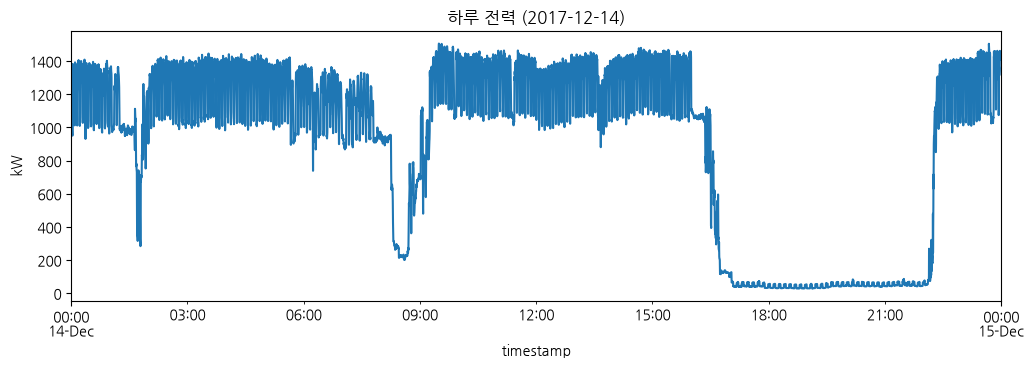

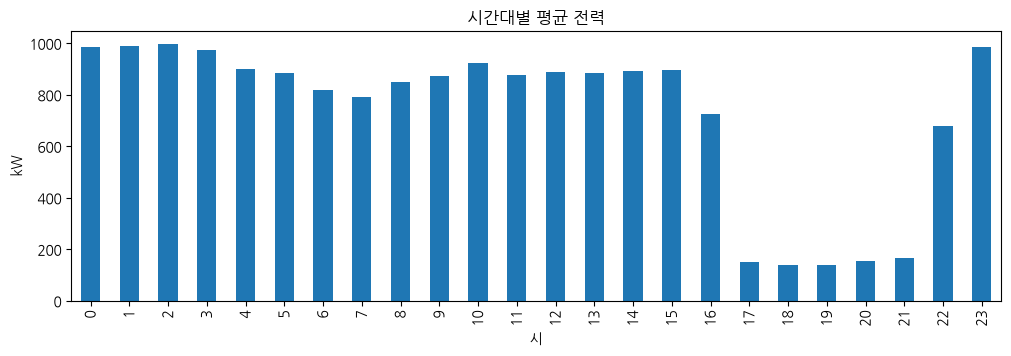

In [24]:
# 하루 예시
days = steps.index.normalize().unique()
day = days[3]
steps[day:day + pd.Timedelta(days=1)].plot(title=f"하루 전력 ({day:%Y-%m-%d})", ylabel="kW")
plt.show()

# 시간대별 평균
hourly = steps.groupby(steps.index.hour).mean()
hourly.plot(kind="bar", title="시간대별 평균 전력", xlabel="시", ylabel="kW")
plt.show()

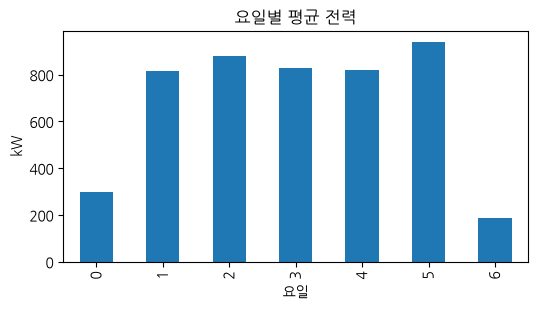

In [25]:
# 요일별 평균 (0=월 ... 6=일)
weekday = steps.groupby(steps.index.dayofweek).mean()
weekday.plot(kind="bar", title="요일별 평균 전력", xlabel="요일", ylabel="kW", figsize=(6, 3))
plt.show()

**확인할 것:** 가동 / 정지 시간대, 요일별 차이, 하루 안에서 부하가 얼마나 출렁이는지.

## 4. 15분 구간 평균 분포

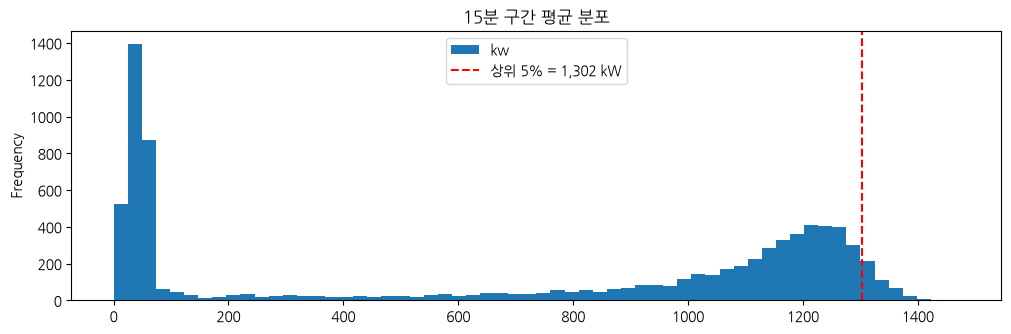

15분 구간 수: 8,077
평가용 목표전력(상위 5%): 1,302 kW


In [26]:
win = steps.resample("15min").mean().dropna()
target_kw = win.quantile(0.95)

win.plot(kind="hist", bins=60, title="15분 구간 평균 분포")
plt.axvline(target_kw, color="red", linestyle="--", label=f"상위 5% = {target_kw:,.0f} kW")
plt.legend()
plt.show()

print(f"15분 구간 수: {len(win):,}")
print(f"평가용 목표전력(상위 5%): {target_kw:,.0f} kW")

시뮬레이터의 목표전력(1,600kW)은 이 데이터에서 거의 넘지 않으므로, 평가에서는 **15분 평균 상위 5%**를 목표전력으로 둔다.
그래야 "막아야 할 피크" 구간이 생겨 놓친 피크·헛경보를 셀 수 있다.

## 5. 학습 샘플 만들기

**상황:** 15분 구간이 진행되는 도중(예: 5분 지난 시점)에 "이번 구간 평균이 얼마가 될지" 예측한다.

- 샘플 1개 = 한 구간 안의 한 예측 시점. 구간 시작 2분 후 ~ 14분까지 **1분 간격**
- 입력 = 예측 시점 **이전**의 데이터로만 만든 값 (미래 값을 쓰면 안 됨)
- 정답 `actual_kw` = 그 구간의 실제 15분 평균

**기존 계산식** `proj_base`: 지금까지 쓴 양 + "지금 전력이 구간 끝까지 그대로 간다"고 가정한 양

$$\text{proj\_base} = \frac{\text{지금까지 합} + \text{지금 전력} \times \text{남은 칸 수}}{90}$$

(15분 = 10초 × 90칸)

In [27]:
df = steps.to_frame("kw")

# 각 칸이 어느 15분 구간에 속하고, 구간 시작 후 몇 번째 칸인지
df["window_start"] = df.index.floor("15min")
df["k"] = (df.index.to_series() - df["window_start"]).dt.total_seconds() // 10   # 0 ~ 89
df["k"] = df["k"].astype(int)

df.head()

,kw,window_start,k
timestamp,,,
2017-12-11 18:43:50,0.008754,2017-12-11 18:30:00,83
2017-12-11 18:44:00,0.006698,2017-12-11 18:30:00,84
2017-12-11 18:44:10,14.058080,2017-12-11 18:30:00,85
2017-12-11 18:44:20,35.669472,2017-12-11 18:30:00,86
2017-12-11 18:44:30,35.792161,2017-12-11 18:30:00,87


In [28]:
# 정답: 구간 실제 평균. 구간 90칸이 모두 있어야 사용
win_mean = df.groupby("window_start")["kw"].mean()
win_count = df.groupby("window_start")["kw"].count()   # count 는 NaN 을 세지 않음
df["actual_kw"] = df["window_start"].map(win_mean)
df["full_window"] = df["window_start"].map(win_count) == 90

print(f"전체 구간: {len(win_count):,}  /  빠짐없는 구간: {(win_count == 90).sum():,}")

전체 구간: 10,850  /  빠짐없는 구간: 4,054


In [29]:
# 예측 시점 '직전'까지의 데이터만 쓰기 위해 한 칸 밀기(shift)
prev = df["kw"].shift(1)

# 현재 상태
df["kw_now"] = prev                                   # 직전 10초 전력
df["mean_1m"] = prev.rolling(6).mean()                # 최근 1분 평균
df["mean_5m"] = prev.rolling(30).mean()               # 최근 5분 평균
df["mean_10m"] = prev.rolling(60).mean()              # 최근 10분 평균
df["std_5m"] = prev.rolling(30).std()                 # 최근 5분 출렁임
df["max_10m"] = prev.rolling(60).max()
df["min_10m"] = prev.rolling(60).min()

# 기울기: 최근 1분 평균이 4분 전보다 얼마나 변했는지 (1칸당 kW)
df["slope"] = (df["mean_1m"] - df["mean_1m"].shift(24)) / 24

# 이번 구간에서 지금까지 쓴 양 (현재 칸 제외한 누적합)
df["used_sum"] = df.groupby("window_start")["kw"].cumsum() - df["kw"]
df["elapsed_ratio"] = df["k"] / 90

# 시간 정보
df["hour"] = df.index.hour
df["dow"] = df.index.dayofweek

In [30]:
remain = 90 - df["k"]   # 남은 칸 수

# 기준 1: 기존 계산식 (지금 전력 유지)
df["proj_base"] = (df["used_sum"] + df["kw_now"] * remain) / 90

# 기준 2: 추세 보정 (지금 기울기대로 계속 오르내린다고 가정, 음수는 0)
future = (df["kw_now"] * remain + 0.5 * df["slope"] * remain ** 2).clip(lower=0)
df["proj_trend"] = (df["used_sum"] + future) / 90

In [31]:
# 예측 시점만 남기기: 구간 시작 2분(12칸) ~ 14분(84칸), 1분(6칸) 간격
points = df[df["k"].isin(range(12, 85, 6)) & df["full_window"]].copy()
points["elapsed_min"] = points["k"] / 6

FEATURES = [
    "elapsed_ratio", "kw_now", "proj_base", "proj_trend",
    "mean_1m", "mean_5m", "mean_10m", "std_5m", "slope", "max_10m", "min_10m",
    "hour", "dow",
]

# 최근 10분 안에 빈 칸이 있으면 특징이 NaN -> 제외
points = points.dropna(subset=FEATURES)

# 모델이 맞힐 값: 실제 평균 - 기존 계산식 (계산식이 얼마나 틀리는지)
points["residual"] = points["actual_kw"] - points["proj_base"]

print(f"샘플 수: {len(points):,}")
points[["window_start", "elapsed_min", "kw_now", "proj_base", "proj_trend", "actual_kw", "residual"]].head(10)

샘플 수: 52,628


,window_start,elapsed_min,kw_now,proj_base,proj_trend,actual_kw,residual
timestamp,,,,,,,
2017-12-11 18:54:00,2017-12-11 18:45:00,9.0,33.482450,37.292285,34.202657,38.554649,1.262364
2017-12-11 18:55:00,2017-12-11 18:45:00,10.0,37.266423,38.644475,35.274599,38.554649,-0.089826
2017-12-11 18:56:00,2017-12-11 18:45:00,11.0,34.202210,37.728866,37.187313,38.554649,0.825783
2017-12-11 18:57:00,2017-12-11 18:45:00,12.0,37.826049,38.574145,38.625650,38.554649,-0.019496
2017-12-11 18:58:00,2017-12-11 18:45:00,13.0,38.429492,38.695711,38.809289,38.554649,-0.141062
2017-12-11 18:59:00,2017-12-11 18:45:00,14.0,34.395567,38.263469,38.272922,38.554649,0.291180
2017-12-11 19:02:00,2017-12-11 19:00:00,2.0,53.985268,53.354157,70.786434,48.639025,-4.715132
2017-12-11 19:03:00,2017-12-11 19:00:00,3.0,62.475129,60.429326,87.134947,48.639025,-11.790301
2017-12-11 19:04:00,2017-12-11 19:00:00,4.0,49.116746,49.781335,60.806652,48.639025,-1.142310


In [32]:
# 날짜 기준 분할: 앞 70% 학습 / 다음 15% 검증 / 마지막 15% 시험
# 랜덤으로 섞으면 같은 구간이 학습·시험에 동시에 들어가 성능이 부풀려진다
dates = sorted(points.index.normalize().unique())
n_train = int(len(dates) * 0.70)
n_valid = int(len(dates) * 0.15)

train_dates = dates[:n_train]
valid_dates = dates[n_train:n_train + n_valid]

day_of_point = points.index.normalize()
points["split"] = "test"
points.loc[day_of_point.isin(train_dates), "split"] = "train"
points.loc[day_of_point.isin(valid_dates), "split"] = "valid"

points["split"].value_counts()

split
train    36937
test      9236
valid     6455
Name: count, dtype: int64

## 6. 기존 계산식의 한계

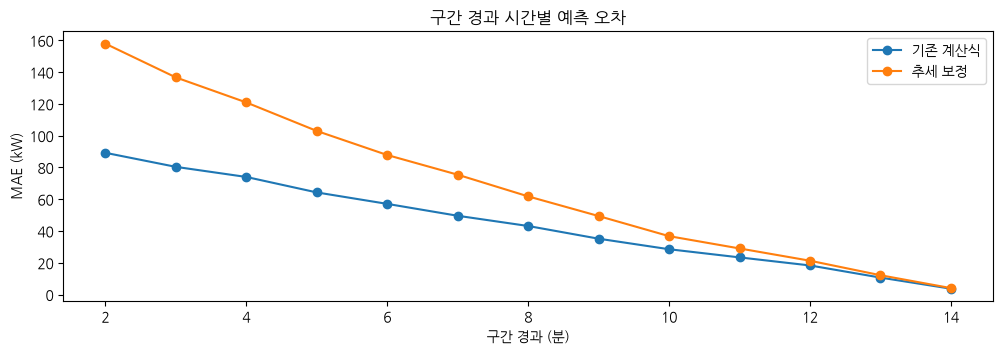

elapsed_min,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0,13.0,14.0
기존 계산식,89.2,80.3,74.0,64.2,57.0,49.5,43.1,35.1,28.5,23.4,18.3,10.6,3.7
추세 보정,157.8,136.6,120.9,102.9,87.8,75.4,61.7,49.4,36.7,29.0,21.3,12.1,4.0


In [33]:
points["err_base"] = (points["proj_base"] - points["actual_kw"]).abs()
points["err_trend"] = (points["proj_trend"] - points["actual_kw"]).abs()

by_min = points.groupby("elapsed_min")[["err_base", "err_trend"]].mean()
by_min.columns = ["기존 계산식", "추세 보정"]

by_min.plot(marker="o", title="구간 경과 시간별 예측 오차", xlabel="구간 경과 (분)", ylabel="MAE (kW)")
plt.show()
by_min.round(1).T

**확인할 것:** 구간 초반일수록 오차가 크다. 남은 시간이 길어서 "지금 전력이 끝까지 간다"는 가정이 많이 틀리기 때문이다.
ML 이 개선할 여지가 가장 큰 곳이 여기다.

## 7. 기본 모델 (LightGBM 기본값)

정답을 직접 맞히지 않고 **잔차(실제 − 기존 계산식)**를 맞힌다. 최종 예측 = 기존 계산식 + 모델이 예측한 잔차.
계산식이 이미 대부분을 맞히므로, 모델은 "얼마나 보정할지"만 배우면 된다.

In [34]:
train = points[points["split"] == "train"]
valid = points[points["split"] == "valid"]
test = points[points["split"] == "test"]

model = LGBMRegressor(random_state=42, verbose=-1)
model.fit(train[FEATURES], train["residual"])

valid_pred = valid["proj_base"] + model.predict(valid[FEATURES])
test_pred = test["proj_base"] + model.predict(test[FEATURES])


def mae(pred, actual):
    return (pred - actual).abs().mean()


compare = pd.DataFrame({
    "기존 계산식": [mae(valid["proj_base"], valid["actual_kw"]), mae(test["proj_base"], test["actual_kw"])],
    "추세 보정": [mae(valid["proj_trend"], valid["actual_kw"]), mae(test["proj_trend"], test["actual_kw"])],
    "LightGBM 기본값": [mae(valid_pred, valid["actual_kw"]), mae(test_pred, test["actual_kw"])],
}, index=["valid MAE (kW)", "test MAE (kW)"])
compare.round(1)

,기존 계산식,추세 보정,LightGBM 기본값
valid MAE (kW),53.8,79.8,36.9
test MAE (kW),42.0,66.0,25.7


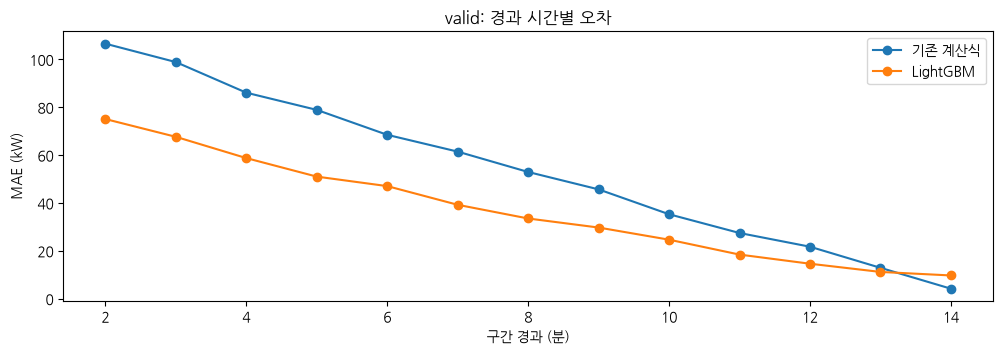

In [35]:
# 경과 시간별 비교 (valid)
valid_err = pd.DataFrame({
    "기존 계산식": (valid["proj_base"] - valid["actual_kw"]).abs(),
    "LightGBM": (valid_pred - valid["actual_kw"]).abs(),
    "elapsed_min": valid["elapsed_min"],
}).groupby("elapsed_min").mean()

valid_err.plot(marker="o", title="valid: 경과 시간별 오차", xlabel="구간 경과 (분)", ylabel="MAE (kW)")
plt.show()

In [36]:
# 피크 판단: 목표전력을 넘을지 맞혔는가 (valid)
actual_peak = valid["actual_kw"] > target_kw

summary = {}
for name, pred in [("기존 계산식", valid["proj_base"]), ("LightGBM", valid_pred)]:
    pred_peak = pred > target_kw
    summary[name] = {
        "실제 피크 시점 수": actual_peak.sum(),
        "놓친 피크": (actual_peak & ~pred_peak).sum(),
        "헛경보": (~actual_peak & pred_peak).sum(),
    }

pd.DataFrame(summary)

,기존 계산식,LightGBM
실제 피크 시점 수,169,169
놓친 피크,40,63
헛경보,396,9


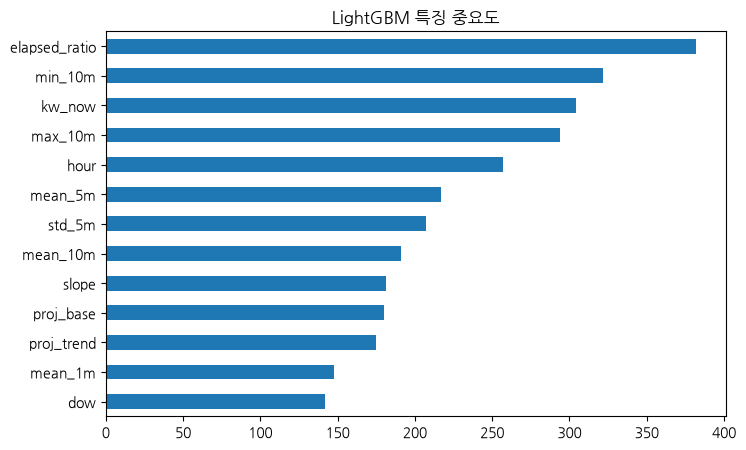

In [37]:
# 어떤 특징이 중요했나 (나눠진 횟수 기준)
importance = pd.Series(model.feature_importances_, index=FEATURES).sort_values()
importance.plot(kind="barh", title="LightGBM 특징 중요도", figsize=(8, 5))
plt.show()

## 8. 정리 (실행 후 직접 적기)

- 데이터:
- 기존 계산식 한계:
- 기본 모델 결과:
- 다음 단계: 하이퍼파라미터 튜닝, 다른 모델 비교